In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier

# load data
df_equipment_corr = pd.read_csv("russia_losses_equipment_correction.csv")
df_equipment = pd.read_csv("russia_losses_equipment.csv")
df_personnel = pd.read_csv("russia_losses_personnel.csv")
df_acled = pd.read_csv("ACLED Data_2026-02-12.csv", sep=";")

for df in [df_equipment_corr, df_equipment, df_personnel, df_acled]:
    print(f"{df.info()}")
    print(f"\n\n\n{df.describe()}")
    print(f"\n\n\n{df.isna().sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   date                     28 non-null     str  
 1   day                      28 non-null     int64
 2   aircraft                 28 non-null     int64
 3   helicopter               28 non-null     int64
 4   tank                     28 non-null     int64
 5   APC                      28 non-null     int64
 6   field artillery          28 non-null     int64
 7   MRL                      28 non-null     int64
 8   drone                    28 non-null     int64
 9   naval ship               28 non-null     int64
 10  submarines               28 non-null     int64
 11  anti-aircraft warfare    28 non-null     int64
 12  special equipment        28 non-null     int64
 13  vehicles and fuel tanks  28 non-null     int64
 14  cruise missiles          28 non-null     int64
 15  personnel          

# Preprocess and Visualize

           event_id_cnty event_date  year  time_precision  \
event_date                                                  
2022-02-24      UKR52179 2022-02-24  2022               1   
2022-02-24      UKR52195 2022-02-24  2022               1   
2022-02-24      UKR52192 2022-02-24  2022               1   
2022-02-24      UKR52194 2022-02-24  2022               1   
2022-02-24      UKR52177 2022-02-24  2022               1   
2022-02-24      UKR52176 2022-02-24  2022               1   
2022-02-24      UKR52206 2022-02-24  2022               1   
2022-02-24      UKR52169 2022-02-24  2022               1   
2022-02-24      UKR52168 2022-02-24  2022               1   
2022-02-24      UKR52167 2022-02-24  2022               1   

                     disorder_type                  event_type  \
event_date                                                       
2022-02-24      Political violence  Explosions/Remote violence   
2022-02-24      Political violence  Explosions/Remote violence   
202

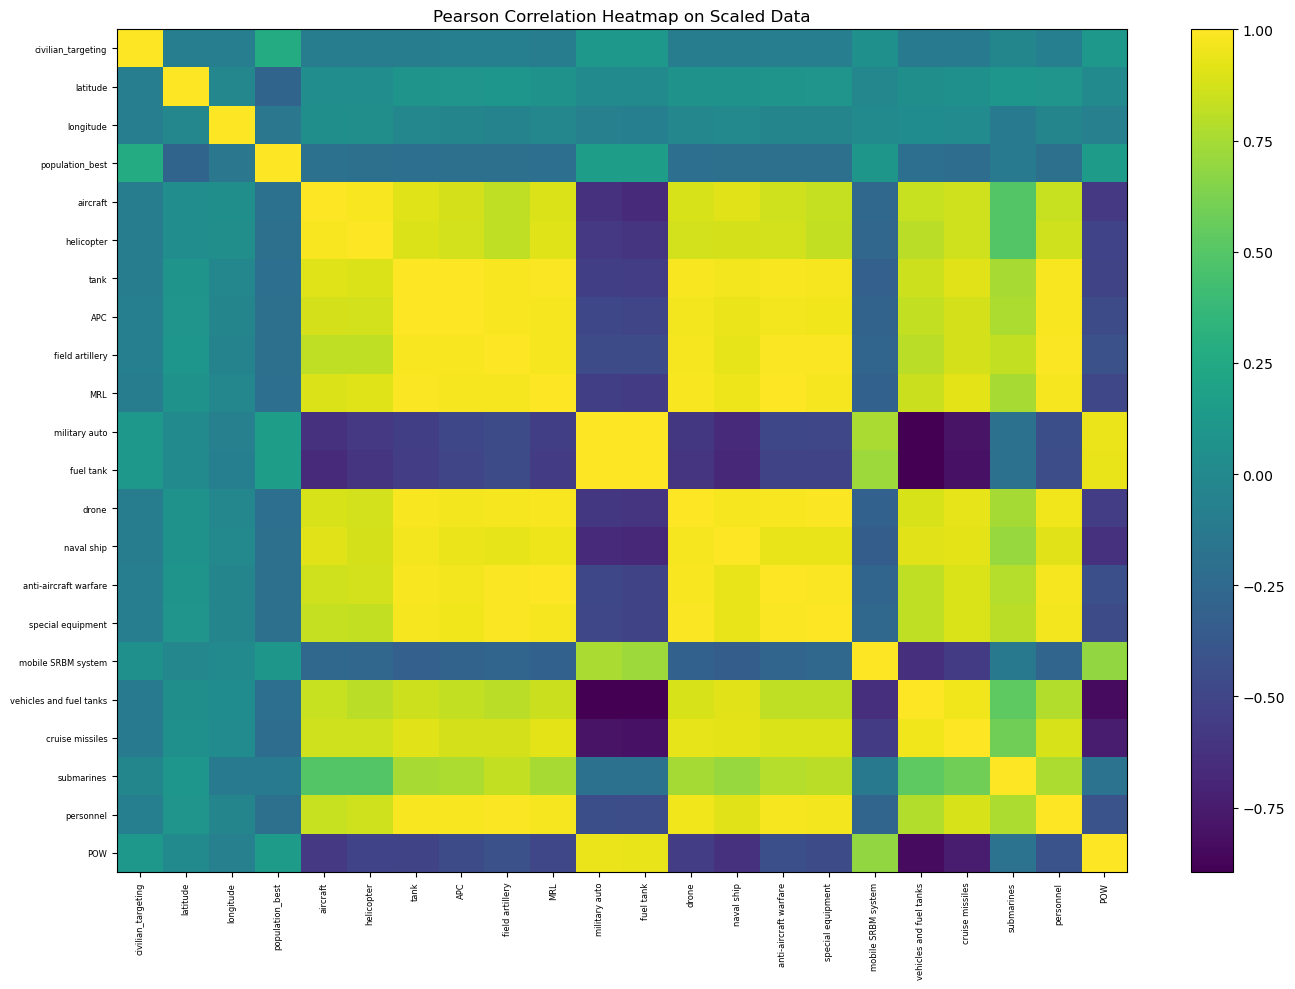

0
0


In [2]:
# this is redundant, we have date already keep in case
def drop_day_cols(df):
    day_cols = [c for c in df.columns if c.strip().lower() == "day"]
    if day_cols:
        df = df.drop(columns=day_cols)
    return df

df_equipment_corr = drop_day_cols(df_equipment_corr)
df_equipment = drop_day_cols(df_equipment)
df_personnel = drop_day_cols(df_personnel)

# ensure to datetime conversion
df_equipment_corr["date"] = pd.to_datetime(df_equipment_corr["date"],
                                           errors="coerce")
df_equipment["date"] = pd.to_datetime(df_equipment["date"],
                                      errors="coerce")
df_personnel["date"] = pd.to_datetime(df_personnel["date"],
                                      errors="coerce")
df_acled["event_date"] = pd.to_datetime(df_acled["event_date"],
                                        errors="coerce")

# left join on ACLED data on date, since we have multiple events per date there
df_merged = (df_acled.merge(df_equipment, how="left",
                            left_on="event_date",right_on="date",
                            suffixes=("", "_equip"))
                            .merge(df_personnel, how="left",
                                   left_on="event_date", right_on="date",
                                   suffixes=("", "_pers"))
                                   .merge(df_equipment_corr, how="left",
                                          left_on="event_date",
                                          right_on="date",
                                          suffixes=("", "_corr")))

# drop duplicate date entries in merged data
for c in ["date", "date_pers", "date_corr"]:
    if c in df_merged.columns:
        df_merged = df_merged.drop(columns=[c])

# set index on event_date from ACLED
df_merged = df_merged.set_index("event_date", drop=False)

print(df_merged.head(10))

# add up the equipment corrections to the equipment estimates
corr_cols = [i for i in df_merged.columns if i.endswith("_corr")]
for c in corr_cols:
    # remove the sufix
    prefix = c[:-5]
    if prefix in df_merged.columns:
        # sum up the corrections to the correct col name
        df_merged[prefix] = (pd.to_numeric(df_merged[prefix],
                                           errors="coerce").fillna(0)
                                           + pd.to_numeric(df_merged[c],
                                                           errors="coerce")\
                                                            .fillna(0))

# drop corrections
df_merged = df_merged.drop(columns=corr_cols, errors="ignore")

# drop these we dont need it
drop_cols = ["greatest losses direction", "greatest loss direction",
             "admin1", "admin 1", "admin_1","admin2", "admin 2", "admin_2",
             "admin3", "admin 3", "admin_3","tags",]

df_merged = df_merged.drop(columns=
                           [c for c in drop_cols if c in df_merged.columns],
                           errors="ignore")

# dropna, we need this for analysis and have enough data to drop 5.92% of it
if "population_best" in df_merged.columns:
    df_merged = df_merged.dropna(subset=["population_best"])


# fill nans with 0, as it means a no entry, we interpret this as 0 equipment
impute_0 = ["military auto", "fuel tank", "special equipment",
    "mobile SRBM system", "mobile SRBM","vehicles and fuel tanks",
    "vehicle and fule tank", "cruise missiles", "submarines", "POW",]

for c in impute_0:
    if c in df_merged.columns:
        df_merged[c] = pd.to_numeric(df_merged[c], errors="coerce").fillna(0)

# 1 for yes, and 0 for absence of it
if "civilian_targeting" in df_merged.columns:
    df_merged["civilian_targeting"] = (df_merged["civilian_targeting"]
                                       .astype(str)
                                       .str.contains("Civilian targeting",
                                                     case=False, na=False)
                                       .astype(int))

# regex match the actors, there are 4 fields for actors, we categorize them
# as Ukraine = 0, russia = 1, militia = 2, other=3
re_ukr = re.compile(
    r"\bukrain(e|ian)?\b|military forces of ukraine|(\bukr\b)", re.I)
re_rus = re.compile(
    r"\brussia(n)?\b|military forces of russia|(\brus\b)", re.I)
re_mil = re.compile(
    r"\bmilitia\b|people'?s militia|\bdpr\b|\blpr\b", re.I)

def actor_to_category(x):
    if pd.isna(x):
        return 3
    s = str(x)
    if re_ukr.search(s):
        return 0
    if re_rus.search(s):
        return 1
    if re_mil.search(s):
        return 2
    return 3

for c in ["actor1", "actor2", "assoc_actor_1", "assoc_actor_2"]:
    if c in df_merged.columns:
        df_merged[c] = df_merged[c].apply(actor_to_category).astype(int)

# we drop some more columns which are redundant or will not be useful
df_merged = df_merged.drop(columns=[c for c in
                                    ["year", "time_precision"] 
                                    if c in df_merged.columns],
                                    errors="ignore")
df_merged = df_merged.drop(columns=[c for c in
                                    ["iso", "region", "country", "location"] 
                                    if c in df_merged.columns],
                                    errors="ignore")
df_merged = df_merged.drop(columns=[c for c in
                                    ["geo_precision"] 
                                    if c in df_merged.columns],
                                    errors="ignore")
df_merged = df_merged.drop(columns=[c for c in
                                    ["notes", "personnel*"]
                                    if c in df_merged.columns],
                                    errors="ignore")
df_merged = df_merged.drop(columns=[c for c in
                                    ["timestamp"]
                                    if c in df_merged.columns],
                                    errors="ignore")

# cols to one hot encode, they are nominal categorical variables
ohe = ["disorder_type", "event_type", "sub_event_type","actor1",
            "assoc_actor_1", "inter1", "actor2", "assoc_actor_2", "inter2",
            "interaction", "source", "source_scale",
            ]
ohe = [c for c in ohe if c in df_merged.columns]
for c in ohe:
    df_merged[c] = df_merged[c].astype("category")

df_processed = pd.get_dummies(df_merged, columns=ohe, dummy_na=False)

# if any nans remain, impute 0, should be 0
final_nans = df_processed.select_dtypes(include=["number"]).columns.tolist()
df_processed[final_nans] = df_processed[final_nans].fillna(0)

print(f"NAs:  {df_processed.isna().sum().sum()}")

df_modeling = df_processed.copy()

# get target variable
y = pd.to_numeric(df_modeling["fatalities"], errors="coerce")

# drop target for scaling and ensure we pull only numerics
X = df_modeling.select_dtypes(include=[np.number]).copy()
X = X.drop(columns=["fatalities"], errors="ignore")

# we dont have negative values for the log transform
cols = [c for c in X.columns if (X[c].min(skipna=True) >= 0)]

X_log = X.copy()
X_log[cols] = np.log1p(X_log[cols])

# standard scaling after log transform
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)
df_scaled = pd.DataFrame(X_scaled, columns=X.columns, index=df_modeling.index)
# add back unscaled target
df_scaled["fatalities"] = y

print(f"shape: {df_scaled.shape}")

# pearson correlation diagram for scaled data
feature_cols = [c for c in df_scaled.columns if c != "fatalities"]
corr = df_scaled[feature_cols].corr(method="pearson")

plt.figure(figsize=(14, 10))
plt.imshow(corr.values, aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90, fontsize=6)
plt.yticks(range(len(corr.index)), corr.index, fontsize=6)
plt.title("Pearson Correlation Heatmap on Scaled Data")
plt.tight_layout()
plt.show()

out_path = "processed_merged_event_level.csv"
df_processed.to_csv(out_path, index=False)


scaled_out_path = "processed_merged_event_level_scaled.csv"
df_scaled.to_csv(scaled_out_path, index=False)

# sanity check
print(df_processed.isna().sum().sum())
print(df_scaled.isna().sum().sum())

In [3]:
df_scaled.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 154462 entries, 2022-02-24 to 2025-02-12
Data columns (total 23 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   civilian_targeting       154462 non-null  float64
 1   latitude                 154462 non-null  float64
 2   longitude                154462 non-null  float64
 3   population_best          154462 non-null  float64
 4   aircraft                 154462 non-null  float64
 5   helicopter               154462 non-null  float64
 6   tank                     154462 non-null  float64
 7   APC                      154462 non-null  float64
 8   field artillery          154462 non-null  float64
 9   MRL                      154462 non-null  float64
 10  military auto            154462 non-null  float64
 11  fuel tank                154462 non-null  float64
 12  drone                    154462 non-null  float64
 13  naval ship               154462 non-null  float64
 14 

# PCA and KNN

Variance Explained [0.63641905 0.12479407]
Variance Ratio: 0.7612131166261965


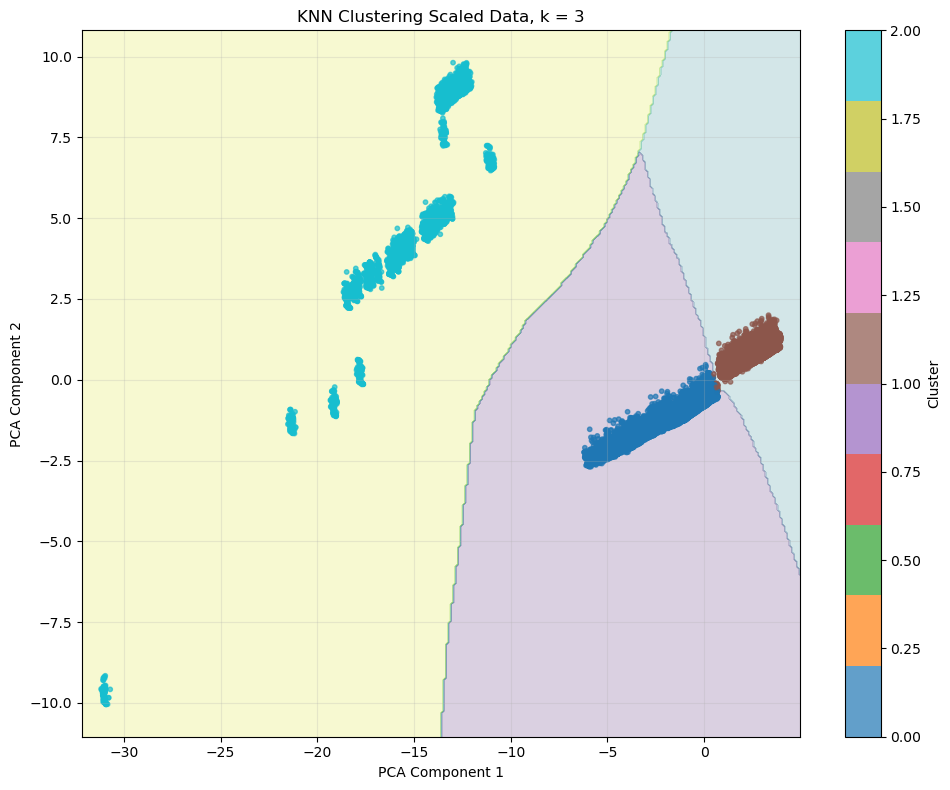

top 10 features for PC1:
drone                    0.262157
naval ship               0.261248
tank                     0.261209
MRL                      0.260854
cruise missiles          0.259802
anti-aircraft warfare    0.255931
APC                      0.255511
special equipment        0.254767
field artillery          0.253287
personnel                0.251484
Name: PC1, dtype: float64

top 10 features for PC2:
military auto              0.424410
POW                        0.416806
fuel tank                  0.412568
mobile SRBM system         0.411071
submarines                 0.278010
vehicles and fuel tanks    0.192443
personnel                  0.174370
field artillery            0.173210
anti-aircraft warfare      0.155049
special equipment          0.150639
Name: PC2, dtype: float64


In [4]:
X = df_scaled.copy()
X = X.drop(columns=["fatalities"])
X_scaled = X.values
# show a PCA visual overlayed with k = 3 segmentation
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_scaled)

# model captures a great deal of variance
print("Variance Explained", pca.explained_variance_ratio_)
print("Variance Ratio:", pca.explained_variance_ratio_.sum())

k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)
knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_2d, cluster_labels)
x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))

Z = knn.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(10, 8))
plt.contourf(xx, yy, Z, alpha=0.2)

# plot
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=cluster_labels, cmap="tab10",
                      s=10, alpha=0.7)

plt.title("KNN Clustering Scaled Data, k = 3")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

features = pd.DataFrame(pca.components_.T, columns=["PC1", "PC2"],
                        index=X.columns)

print("top 10 features for PC1:")
print(features["PC1"].abs().sort_values(ascending=False).head(10))

print("\ntop 10 features for PC2:")
print(features["PC2"].abs().sort_values(ascending=False).head(10))

# Distributions of most important features


Top 10 variables most correlated with fatalities (on scaled features):
population_best          0.101510
latitude                 0.070083
longitude                0.025367
submarines               0.024153
field artillery          0.016380
APC                      0.015288
special equipment        0.013815
anti-aircraft warfare    0.013788
POW                      0.013752
personnel                0.013522
Name: fatalities, dtype: float64


/var/folders/xf/h4xr85dn3d1d6gxjpf_rl78m0000gn/T/ipykernel_88269/3113051843.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=["Fatalities = 0", "Fatalities > 0"])


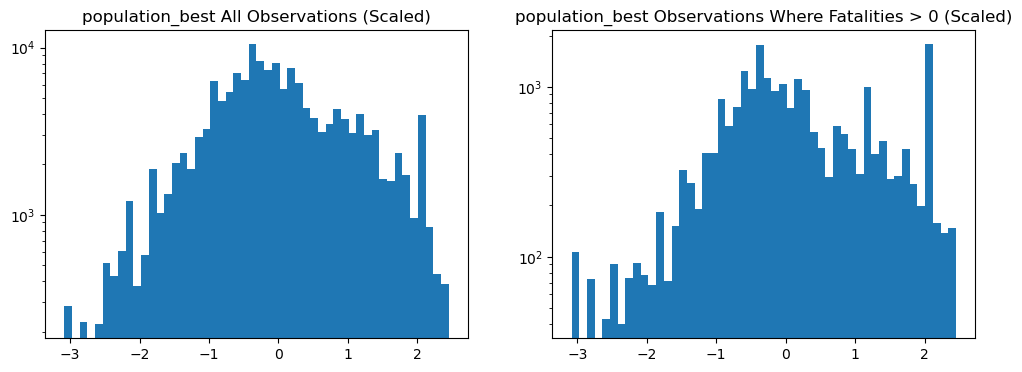

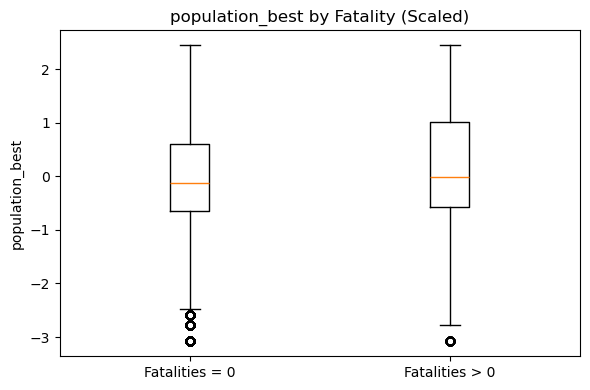

/var/folders/xf/h4xr85dn3d1d6gxjpf_rl78m0000gn/T/ipykernel_88269/3113051843.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=["Fatalities = 0", "Fatalities > 0"])


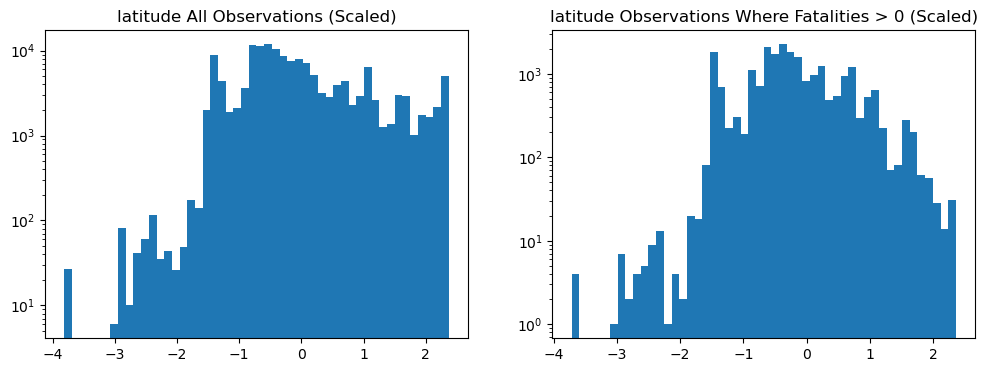

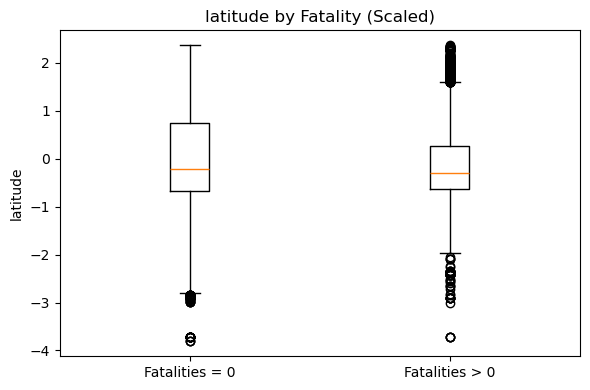

/var/folders/xf/h4xr85dn3d1d6gxjpf_rl78m0000gn/T/ipykernel_88269/3113051843.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=["Fatalities = 0", "Fatalities > 0"])


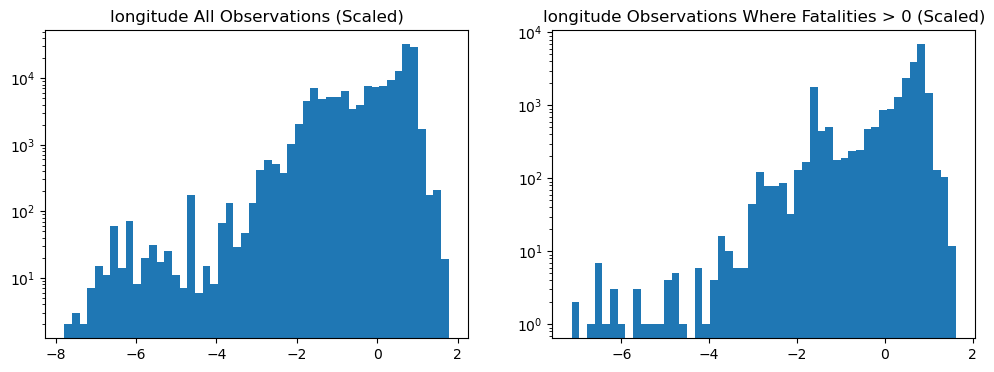

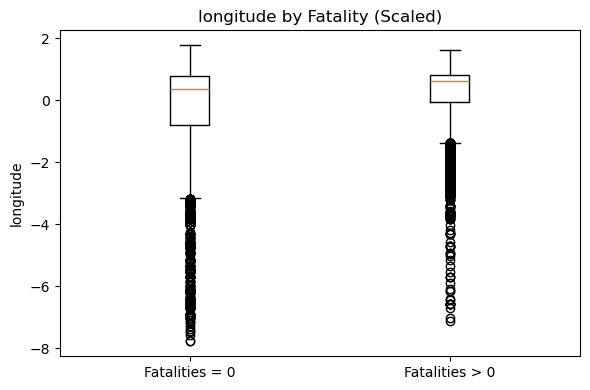

/var/folders/xf/h4xr85dn3d1d6gxjpf_rl78m0000gn/T/ipykernel_88269/3113051843.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=["Fatalities = 0", "Fatalities > 0"])


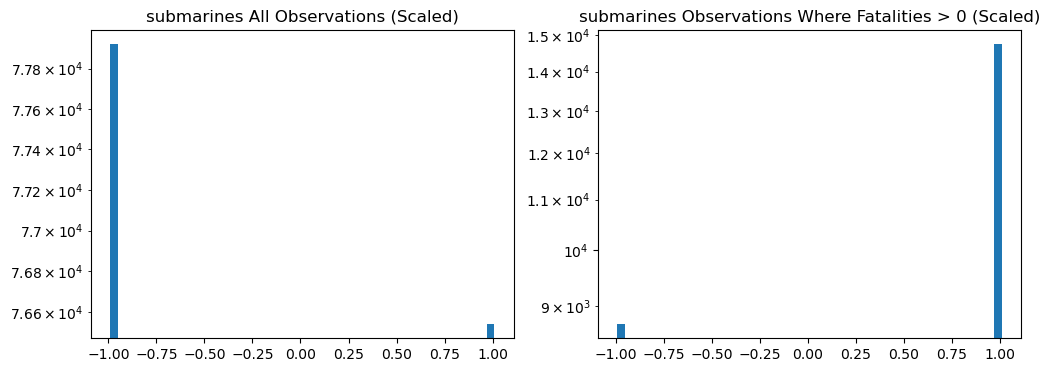

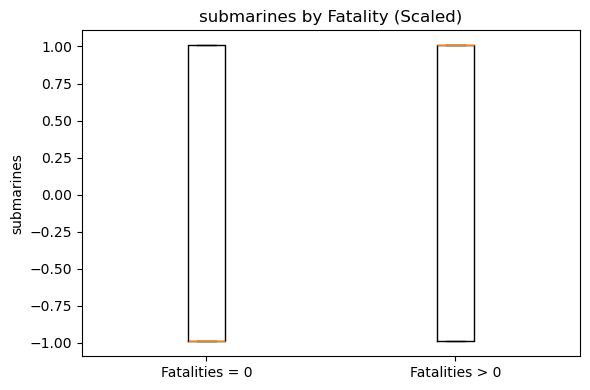

/var/folders/xf/h4xr85dn3d1d6gxjpf_rl78m0000gn/T/ipykernel_88269/3113051843.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=["Fatalities = 0", "Fatalities > 0"])


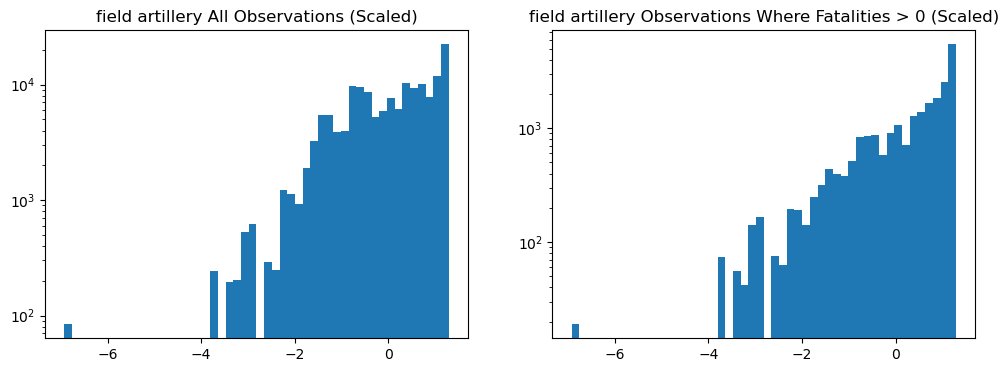

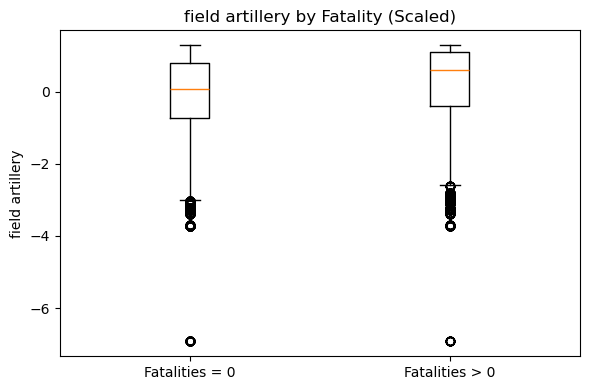

/var/folders/xf/h4xr85dn3d1d6gxjpf_rl78m0000gn/T/ipykernel_88269/3113051843.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=["Fatalities = 0", "Fatalities > 0"])


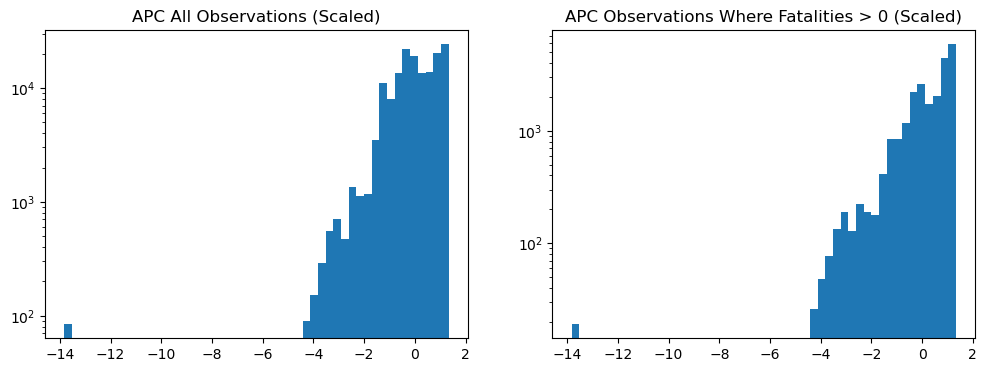

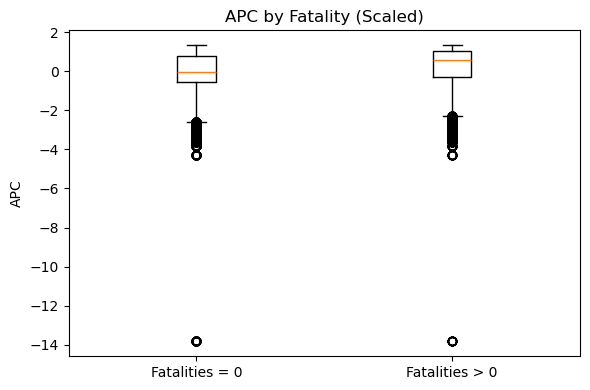

/var/folders/xf/h4xr85dn3d1d6gxjpf_rl78m0000gn/T/ipykernel_88269/3113051843.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=["Fatalities = 0", "Fatalities > 0"])


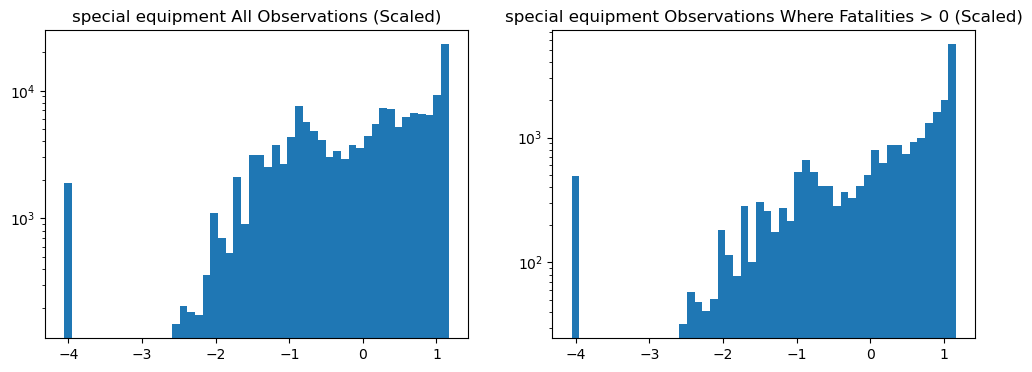

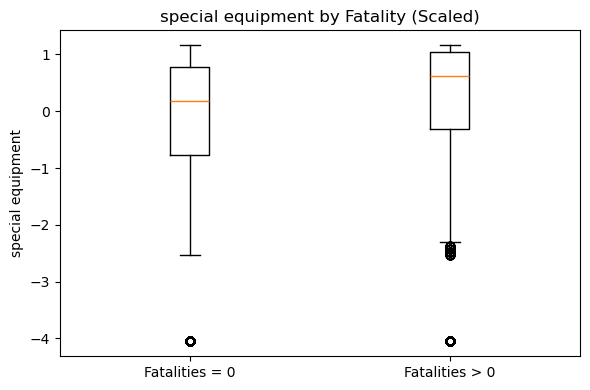

/var/folders/xf/h4xr85dn3d1d6gxjpf_rl78m0000gn/T/ipykernel_88269/3113051843.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=["Fatalities = 0", "Fatalities > 0"])


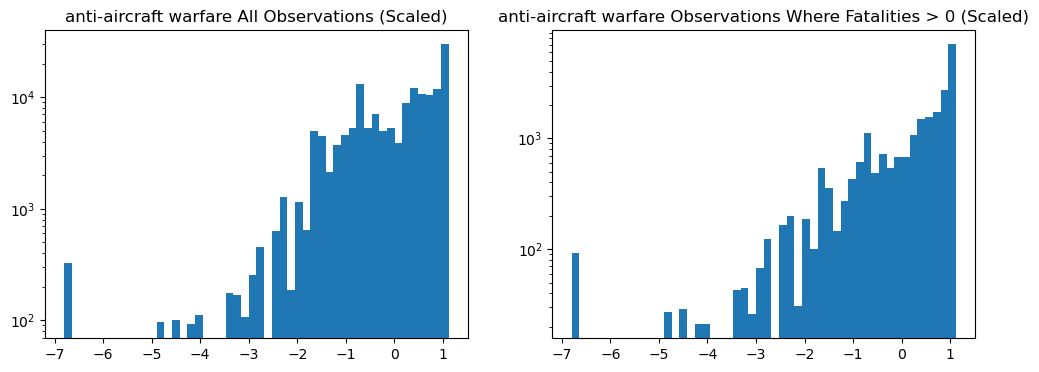

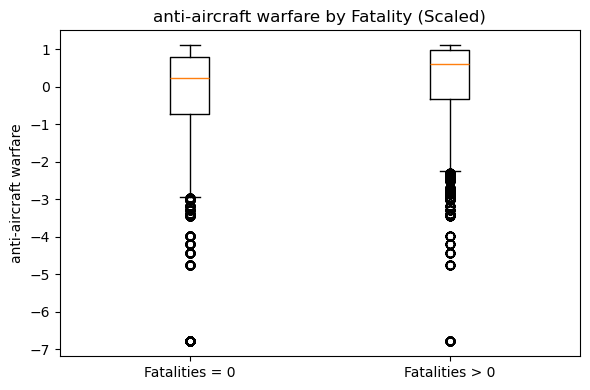

/var/folders/xf/h4xr85dn3d1d6gxjpf_rl78m0000gn/T/ipykernel_88269/3113051843.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=["Fatalities = 0", "Fatalities > 0"])


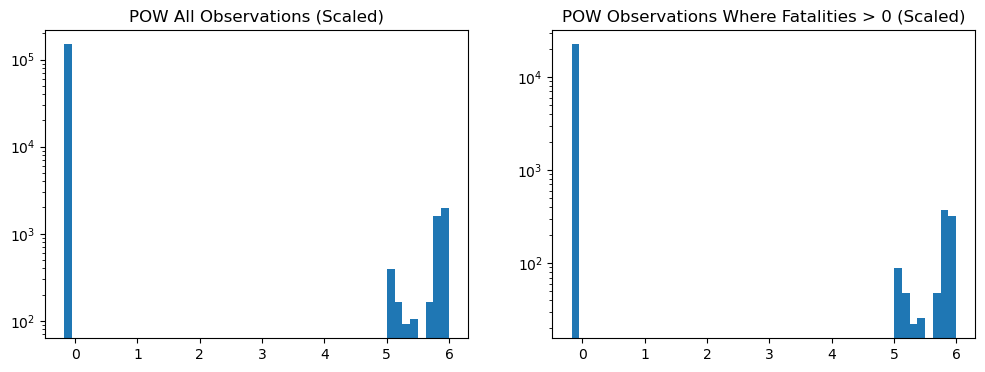

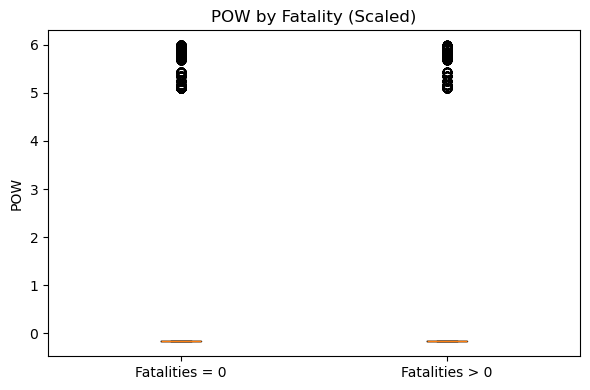

/var/folders/xf/h4xr85dn3d1d6gxjpf_rl78m0000gn/T/ipykernel_88269/3113051843.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=["Fatalities = 0", "Fatalities > 0"])


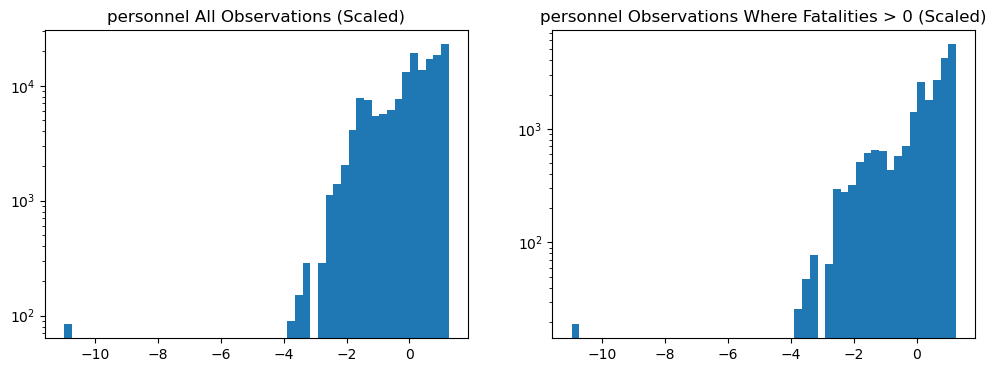

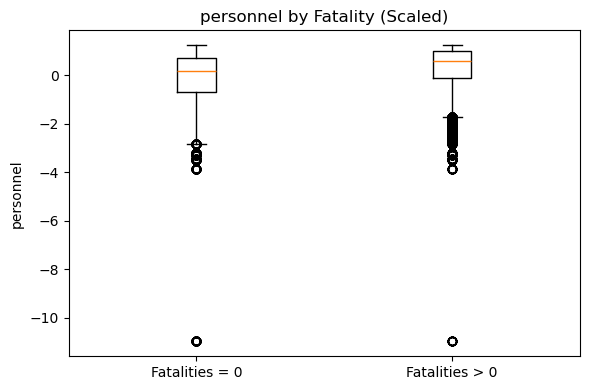

In [5]:
X = df_scaled.copy()

correlation = X.corr()["fatalities"].drop("fatalities")
highest = correlation.abs().sort_values(ascending=False).head(10)

print("\nTop 10 variables most correlated with " \
"fatalities (on scaled features):")
print(highest)

top = highest.index.tolist()

# plot distribution for each of the top features
for c in top:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(df_scaled[c], bins=50)
    axes[0].set_title(f"{c} All Observations (Scaled)")
    axes[0].set_yscale("log")
    axes[1].hist(df_scaled.loc[df_scaled["fatalities"] > 0, c],
                 bins=50)
    # we do this since most fatalities are 0
    axes[1].set_title(f"{c} Observations Where Fatalities > 0 (Scaled)")
    axes[1].set_yscale("log")
    plt.figure(figsize=(6, 4))
    
    data_to_plot = [
        df_scaled.loc[df_scaled["fatalities"] == 0, c],
        df_scaled.loc[df_scaled["fatalities"] > 0, c]]
    # gives 3 charts per each predictor
    plt.boxplot(data_to_plot, labels=["Fatalities = 0", "Fatalities > 0"])
    plt.title(f"{c} by Fatality (Scaled)")
    plt.ylabel(c)
    plt.tight_layout()
    plt.show()